# [Bonus Tasks](svm_segm.ipynb)

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [4]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [5]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [6]:
def create_data_matrix(img):
    patches = skimage.util.view_as_blocks(img, block_shape=patch_sizes)

    X = patches.reshape(-1, patch_sizes[0] * patch_sizes[1])

    return X

**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [25]:
def create_gt_labels_vector(gt_img):
    patches = create_data_matrix(gt_img)

    foreground_fraction = np.mean(patches > 0, axis=1)

    y = np.where(foreground_fraction > 0.5, 1,
                 np.where(foreground_fraction == 0, -1, 0))

    return y

**[Task 1.3.]()** Create the SVM classifier:

In [ ]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

#this is the machine learning algorithm

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

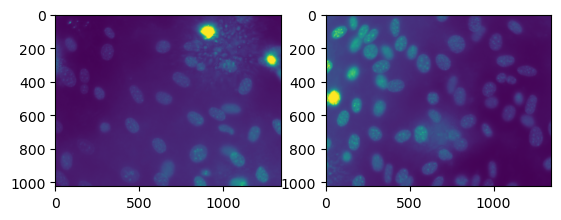

In [27]:
img1 = plt.imread('data/NIH3T3/im/dna-33.png')
img2 = plt.imread('data/NIH3T3/im/dna-44.png')

plt.figure()
plt.subplot(1,2,1)
plt.imshow(img1)
plt.subplot(1,2,2)
plt.imshow(img2)
plt.show()



In [28]:
X1 = create_data_matrix(img1)
X2 = create_data_matrix(img2)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

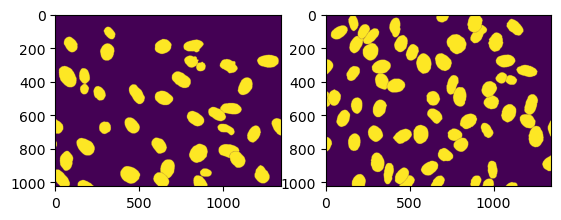

In [34]:
gt_1 = plt.imread('data/NIH3T3/gt/33.png')
gt_2 = plt.imread('data/NIH3T3/gt/44.png')

plt.figure()
plt.subplot(1,2,1)
plt.imshow(gt_1)
plt.subplot(1,2,2)
plt.imshow(gt_2)
plt.show()

In [36]:
y1 = create_gt_labels_vector(gt_1)
y2 = create_gt_labels_vector(gt_2)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [37]:
X1_filtered = X1[y1 != 0]
y1_filtered = y1[y1 != 0]

X2_filtered = X2[y2 != 0]
y2_filtered = y2[y2 != 0]

X = np.concatenate((X1_filtered, X2_filtered))
y = np.concatenate((y1_filtered, y2_filtered))

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [39]:
clf.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[-1, 1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1024
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


**[Task 1.4.]()** Implement the function `predict_image`:

In [45]:
def predict_image (img):
    matrix = create_data_matrix(img) #creating matrix

    y_pred = clf.predict(matrix) #model generating prediction for y label

    patch_mask = (y_pred == 1) #creates boolean array where True when label = 1 and False otherwise
    
    patch_grid = patch_mask.reshape(
        img.shape[0] // patch_sizes[0],
        img.shape[1] // patch_sizes[1]
    )                                     #this restores the original image shape, but it's now 1/4 of what it was (each side half as long)

    result = np.repeat(patch_grid, patch_sizes[0], axis=0) #this brings the image back to og size by repeating the rows and cols
    result = np.repeat(result, patch_sizes[1], axis=1)

    return result


Test your implementation:

C:\Users\gusta\AppData\Local\Temp\ipykernel_4236\1684334352.py:6: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
C:\Users\gusta\AppData\Local\Temp\ipykernel_4236\1684334352.py:6: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))


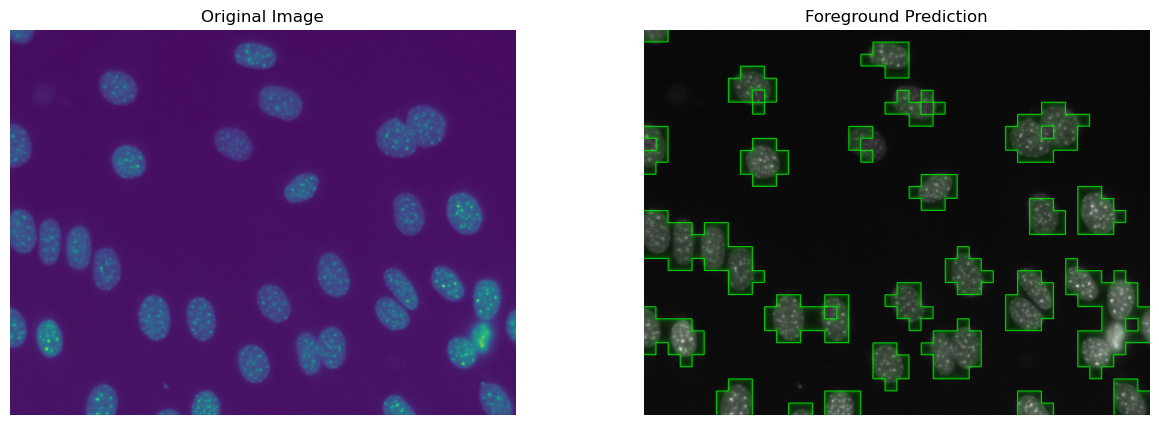

In [53]:
test_img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(test_img)

plt.figure(figsize=(15,5))
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(test_img)
plt.title('Original Image')

plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(blend_result(test_img, seg))
plt.title('Foreground Prediction')

plt.savefig('result_foreground_prediction.png')
plt.show()


**[Task 1.5.]()** Perform batch processing:

In [ ]:
sequence = np.array([28, 29, 33, 44, 46, 49])

for i in sequence:
    img = plt.imread(f'data/NIH3T3/im/dna-{i}')
    gt = plt.imread(f'data/NIH3T3/gt/dna-{i}')
    seg = predict_image(img)

    dice = (2 * (h_bool & bi_image).sum() / (bi_image.sum() + h_bool.sum())) # change this for dice coefficient of the segmentation result